## IMPORTING PACKAGES:

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

In [5]:
from sklearn.compose import TransformedTargetRegressor

In [6]:
from sklearn.linear_model import SGDRegressor, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

In [7]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

## FUNCTION FOR CLEANING TEST:

In [ ]:
# def clean(data):
#     df = data.copy()

#     df= df.drop(columns='id')
#     df = df.drop_duplicates()


#     mask = df['airline'].isna() & df['flight'].str.startswith(("6.00E", "0.00E"))
#     df.loc[mask, 'airline'] = 'Indigo'

#     codes = {'UK': 'Vistara', 'AI': 'Air_India', 'G8': 'GO_FIRST',
#             'I5': 'AirAsia', 'SG': 'SpiceJet'}

#     prefix = df['flight'].str.split('-').str[0]
#     df['airline'] = df['airline'].fillna(prefix.map(codes))

#     mask = df['stops'].isna() & ~df['flight'].str.startswith(("6.00E", "0.00E"))
#     df.loc[mask, 'stops'] = df.groupby('flight')['stops'].transform(
#     lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

#     drop = df['stops'].isna() & (df['airline'] != 'Indigo')
#     df = df[~drop]

#     corrupted = df['flight'].str.startswith(("6.00E", "0.00E"))
#     rules = {'stops': 'mode', 'departure': 'mode', 'duration': 'median'}
#     for col, how in rules.items():
#         if how == 'mode':
#                 fill = df.groupby('flight')[col].transform(
#                 lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
#         else:
#                 fill = df.groupby('flight')[col].transform('median')

#         mask = df[col].isna() & ~corrupted
#         df.loc[mask, col] = fill[mask]

#     keys_d = ['airline', 'source', 'destination', 'class', 'stops']
#     mask = df['duration'].isna()
#     df.loc[mask, 'duration'] = df.groupby(keys_d)['duration'].transform('median')[mask]
#     df = df[~(df['duration'].isna() & df['stops'].isna())]

#     keys = ['airline', 'source', 'destination', 'arrival', df['duration'].round()]
#     mask = df['departure'].isna()
#     df.loc[mask, 'departure'] = df.groupby(keys)['departure'].transform(
#     lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]
#     df = df[df['departure'].notna()]

#     keys_s = ['airline', 'source', 'destination', 'class', df['duration'].round()]
#     mask = df['stops'].isna()
#     df.loc[mask, 'stops'] = df.groupby(keys_s)['stops'].transform(
#     lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]
#     df = df[df['stops'].notna()]


#     df = df.drop(columns='flight')
#     return df

corrected version for test data

In [42]:
def clean_test(data):
    df = data.copy()

    df = df.drop(columns='id')

    mask = df['airline'].isna() & df['flight'].str.startswith(("6.00E", "0.00E"))
    df.loc[mask, 'airline'] = 'Indigo'

    codes = {'UK': 'Vistara', 'AI': 'Air_India', 'G8': 'GO_FIRST',
             'I5': 'AirAsia', 'SG': 'SpiceJet'}

    prefix = df['flight'].str.split('-').str[0]
    df['airline'] = df['airline'].fillna(prefix.map(codes))

    corrupted = df['flight'].str.startswith(("6.00E", "0.00E"))
    rules = {'stops': 'mode', 'departure': 'mode', 'duration': 'median'}
    for col, how in rules.items():
        if how == 'mode':
            fill = df.groupby('flight')[col].transform(
                lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
        else:
            fill = df.groupby('flight')[col].transform('median')

        mask = df[col].isna() & ~corrupted
        df.loc[mask, col] = fill[mask]

    keys_d = ['airline', 'source', 'destination', 'class', 'stops']
    mask = df['duration'].isna()
    df.loc[mask, 'duration'] = df.groupby(keys_d)['duration'].transform('median')[mask]

    keys = ['airline', 'source', 'destination', 'arrival', df['duration'].round()]
    mask = df['departure'].isna()
    df.loc[mask, 'departure'] = df.groupby(keys)['departure'].transform(
        lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

    keys_s = ['airline', 'source', 'destination', 'class', df['duration'].round()]
    mask = df['stops'].isna()
    df.loc[mask, 'stops'] = df.groupby(keys_s)['stops'].transform(
        lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

    # leftovers: fill, never drop
    median_dur = df.groupby(['airline', 'source', 'destination', 'class'])['duration'].transform('median')
    df['duration'] = df['duration'].fillna(median_dur).fillna(df['duration'].median())
    for col in ['stops', 'departure']:
        df[col] = df[col].fillna(df[col].mode()[0])

    # days_left stays NaN: the pipeline's SimpleImputer handles it

    df = df.drop(columns='flight')
    return df

## DATASET:

In [8]:
df = pd.read_csv("train.csv").drop(columns='id')
df.head()

,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


# IDENTIFY DATATYPES OF DIFFERENT COLUMNS:

In [9]:
print(df.info())
print(df.columns.to_list())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   airline      35387 non-null  str    
 1   flight       40000 non-null  str    
 2   source       40000 non-null  str    
 3   departure    35208 non-null  str    
 4   stops        37681 non-null  str    
 5   arrival      40000 non-null  str    
 6   destination  40000 non-null  str    
 7   class        40000 non-null  str    
 8   duration     36987 non-null  float64
 9   days_left    35562 non-null  float64
 10  price        40000 non-null  int64  
dtypes: float64(2), int64(1), str(8)
memory usage: 3.4 MB
None
['airline', 'flight', 'source', 'departure', 'stops', 'arrival', 'destination', 'class', 'duration', 'days_left', 'price']


# DESCRIPTIVE STATISTICS:

In [339]:
df.describe()

,duration,days_left,price
count,36987.000000,35562.000000,40000.00000
mean,12.004088,26.197936,20801.49025
std,7.108063,13.469232,22729.14842
min,0.830000,1.000000,1105.00000
25%,6.670000,15.000000,4687.00000
50%,11.080000,26.000000,7353.00000
75%,15.920000,38.000000,42521.00000
max,47.080000,49.000000,114704.00000


In [340]:
df[(df['airline']=='Indigo')&(df["flight"].str.startswith(("6.00E")))].shape[0]

573

In [341]:
print(f"no. of rows with Indigo's corrupted 'flight' cell: {df[df['flight'].str.startswith(("6.00E"))].shape[0]}")
print(f"no. of rows with 0.00E in corrupted 'flight' cell: {df[df["flight"].str.startswith("0.00E")].shape[0]}")

no. of rows with Indigo's corrupted 'flight' cell: 652
no. of rows with 0.00E in corrupted 'flight' cell: 5270


In [10]:
print(df.duplicated().sum())
df = df.drop_duplicates()

250


# HANDLING MISSING VALUES:

In [343]:
df.isna().sum() #counting the NaN's

airline        4609
flight            0
source            0
departure      4788
stops          2319
arrival           0
destination       0
class             0
duration       3005
days_left      4195
price             0
dtype: int64

In [11]:
mask = df['flight'].str.startswith("6.00E") & (df['airline'] != 'Indigo')
df.loc[mask, 'airline'].value_counts(dropna=True)

Series([], Name: count, dtype: int64)

All '6.00E' corrupted rows are likely to be Indigo, since Indigo's code is 6E which may have not rendered corrected in csv format.

steps taken to rectify:
- filtering out the 6.00E/0.00E corrupted values in flight
- filling those with missing airline with 'Indigo'

In [12]:
# before: how many missing airlines in corrupted rows
mask = df['airline'].isna() & df['flight'].str.startswith(("6.00E", "0.00E"))
print(mask.sum())                       # expect ~686

# fill
df.loc[mask, 'airline'] = 'Indigo'

# after
print(df['airline'].isna().sum())       # remaining missing (intact codes)

686
3923


For non-Indigo missing vlaues, using their codes from 'flight' column:

In [13]:
codes = {'UK': 'Vistara', 'AI': 'Air_India', 'G8': 'GO_FIRST',
         'I5': 'AirAsia', 'SG': 'SpiceJet'}

prefix = df['flight'].str.split('-').str[0]
df['airline'] = df['airline'].fillna(prefix.map(codes))

print(df['airline'].isna().sum())

0


Checking other missing rows for next step:

In [14]:
df.isna().sum()

airline           0
flight            0
source            0
departure      4788
stops          2319
arrival           0
destination       0
class             0
duration       3005
days_left      4195
price             0
dtype: int64

In [348]:

df[df['stops'].isna() & (df['airline'] == 'SpiceJet') & (df['flight']=="SG-8152")]

,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
154,SpiceJet,SG-8152,Mumbai,Early_Morning,NaN,Morning,Kolkata,Economy,25.75,28.0,5289
195,SpiceJet,SG-8152,Mumbai,Early_Morning,NaN,Morning,Kolkata,Economy,25.75,12.0,7728
4612,SpiceJet,SG-8152,Mumbai,Early_Morning,NaN,Night,Kolkata,Economy,15.67,28.0,5289
27024,SpiceJet,SG-8152,Delhi,Morning,NaN,Night,Kolkata,Economy,11.25,37.0,6129


In [349]:
df[(df['flight']=='SG-8152') & (df['stops'].notna())]['stops'].head()

375      one
1259     one
4769     one
5489    zero
8167     one
Name: stops, dtype: str

In [15]:
mask = df['stops'].isna() & ~df['flight'].str.startswith(("6.00E", "0.00E"))

df.loc[mask, 'stops'] = df.groupby('flight')['stops'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

print(df['stops'].isna().sum())
df.isna().sum()

355


airline           0
flight            0
source            0
departure      4788
stops           355
arrival           0
destination       0
class             0
duration       3005
days_left      4195
price             0
dtype: int64

In [16]:
drop = df['stops'].isna() & (df['airline'] != 'Indigo')
df = df[~drop]
df['stops'].isna().sum()


np.int64(348)

In [17]:
corrupted = df['flight'].str.startswith(("6.00E", "0.00E"))

rules = {'stops': 'mode', 'departure': 'mode', 'duration': 'median'}

for col, how in rules.items():
    if how == 'mode':
        fill = df.groupby('flight')[col].transform(
            lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
    else:
        fill = df.groupby('flight')[col].transform('median')

    mask = df[col].isna() & ~corrupted
    df.loc[mask, col] = fill[mask]


In [18]:
keys_d = ['airline', 'source', 'destination', 'class', 'stops']
mask = df['duration'].isna()
df.loc[mask, 'duration'] = df.groupby(keys_d)['duration'].transform('median')[mask]

df.isna().sum()

airline           0
flight            0
source            0
departure       696
stops           348
arrival           0
destination       0
class             0
duration         26
days_left      4194
price             0
dtype: int64

In [19]:
df = df[~(df['duration'].isna() & df['stops'].isna())]

df.isna().sum()

airline           0
flight            0
source            0
departure       692
stops           322
arrival           0
destination       0
class             0
duration          0
days_left      4193
price             0
dtype: int64

In [20]:
keys = ['airline', 'source', 'destination', 'arrival', df['duration'].round()]

mask = df['departure'].isna()
df.loc[mask, 'departure'] = df.groupby(keys)['departure'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]


df['departure'].isna().sum()

np.int64(27)

In [21]:
df = df[df['departure'].notna()]
df.isna().sum()

airline           0
flight            0
source            0
departure         0
stops           322
arrival           0
destination       0
class             0
duration          0
days_left      4189
price             0
dtype: int64

Now, rerunning mask and imputing for stops now that we have all values filled in for the features it depended on for imputation before:


In [22]:
keys_s = ['airline', 'source', 'destination', 'class', df['duration'].round()]
mask = df['stops'].isna()
df.loc[mask, 'stops'] = df.groupby(keys_s)['stops'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

df.isna().sum()


airline           0
flight            0
source            0
departure         0
stops             1
arrival           0
destination       0
class             0
duration          0
days_left      4189
price             0
dtype: int64

In [23]:
df = df[df['stops'].notna()]
df.isna().sum()

airline           0
flight            0
source            0
departure         0
stops             0
arrival           0
destination       0
class             0
duration          0
days_left      4189
price             0
dtype: int64

days_left will undergo SimpleImputer wiht median strategy in the pipeline later on during preprocessing.

# HANDLING DUPLICATES:

Handled this at the start, before imputation itself.

# HANDLING OUTLIERS:

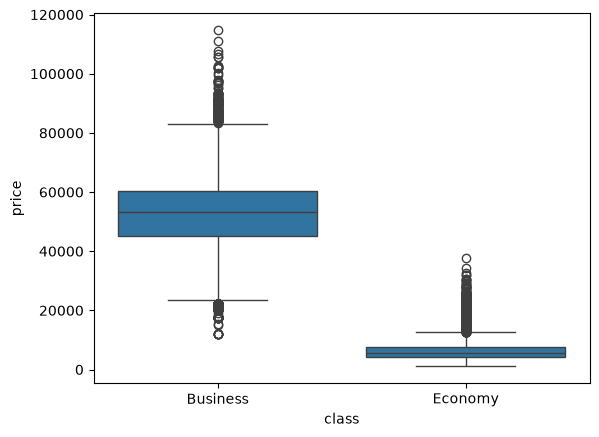

In [359]:
sns.boxplot(data=df, x='class', y='price')
plt.show()

In this prediction project, since prices are sensitive and volatile, I will not be dropping "outliers" even if beyond 1.5*IQR, since they possess informative features that may help with better prediction.

In [360]:
df[(df['class'] == 'Economy') & (df['price'] > 13000)]['days_left'].describe()

count    1594.000000
mean        9.035132
std         7.702570
min         1.000000
25%         4.000000
50%         8.000000
75%        11.000000
max        49.000000
Name: days_left, dtype: float64

These seem like normal data for last minute fares. Hence stronger the argument to not drop outliers.

# VISUALIZATIONS:

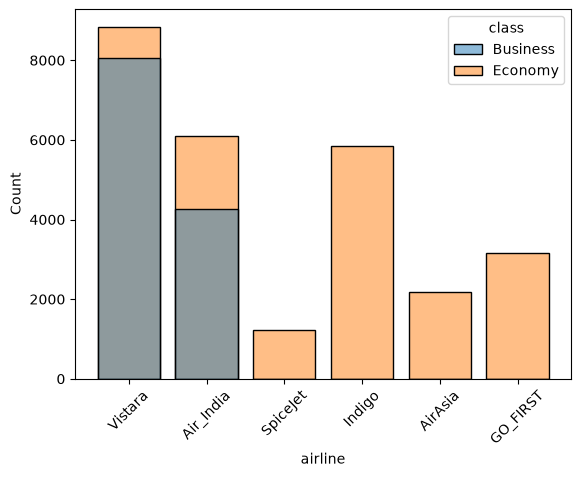

In [361]:
sns.histplot(data=df, x='airline', shrink=0.8,hue='class')
plt.xticks(rotation=45)
plt.show()

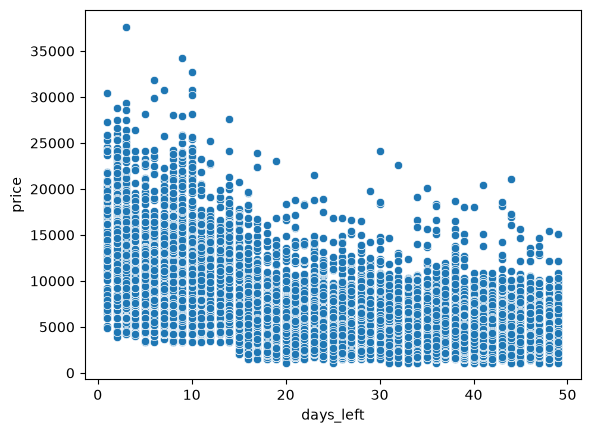

In [362]:
sns.scatterplot(data=df[df['class'] == 'Economy'], x='days_left', y='price')
plt.show()

<Axes: xlabel='price', ylabel='Count'>

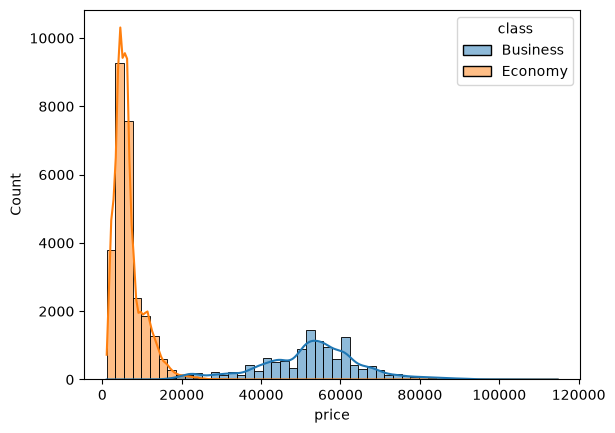

In [363]:
sns.histplot(data=df, x="price", hue="class", kde=True)

<Axes: xlabel='price', ylabel='Count'>

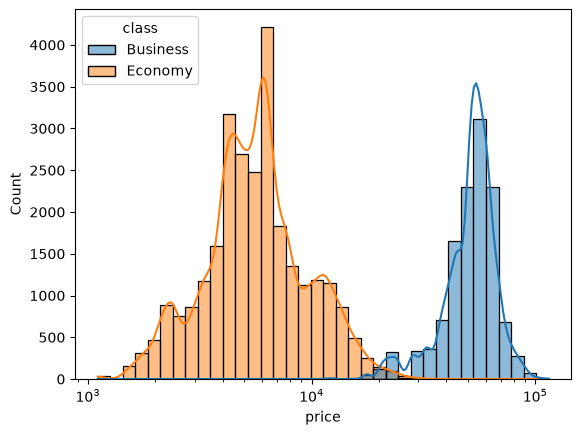

In [364]:
sns.histplot(data=df, x="price", hue="class", log_scale=True, kde=True)

In [365]:
df.head()

,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,12.08,40.0,64173
1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,Indigo,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


# SCALING AND ENCODING:

Splitting to x/y and test/train:

In [24]:
X = df.drop(columns='price')
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['class'])

In [25]:
days = ['days_left']
dur = ['duration']
nom = ['airline', 'source', 'destination', 'departure', 'arrival']
ordc = ['stops', 'class']

pre = ColumnTransformer([
    ('days', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                      ('sc', StandardScaler())]), days),
    ('dur', StandardScaler(), dur),
    ('nom', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nom),
    ('ord', OrdinalEncoder(categories=[['zero', 'one', 'two_or_more'],
                                       ['Economy', 'Business']]), ordc),
])

In [26]:
pre.fit_transform(X_train).shape

(31751, 35)

Price is bimodal in this dataset. So applying TransformedTargetRegressor accrodingly:

In [27]:
def make_model(reg):
    return TransformedTargetRegressor(
        regressor=Pipeline([('pre', pre), ('reg', reg)]),
        func=np.log1p, inverse_func=np.expm1)

# MODEL BUILDING:

7 models are being tested.

In [28]:
P = 'regressor__reg__'

search_spaces = {
    'linreg_sgd': (
        SGDRegressor(penalty=None, max_iter=2000, early_stopping=True, random_state=42),
        {P+'learning_rate': ['invscaling', 'adaptive'],
         P+'eta0': [0.001, 0.01, 0.05]}),

    'poly2': (
        Pipeline([('poly', PolynomialFeatures(degree=2, include_bias=False)),
                  ('ridge', Ridge())]),
        {P+'ridge__alpha': [0.1, 1, 10, 100]}),

    'knn': (
        KNeighborsRegressor(n_jobs=-1),
        {P+'n_neighbors': [3, 5, 10, 20],
         P+'weights': ['uniform', 'distance']}),

    'tree': (
        DecisionTreeRegressor(random_state=42),
        {P+'max_depth': [8, 12, 16, 20, None],
         P+'min_samples_leaf': [1, 3, 5, 10]}),

    'rf': (
        RandomForestRegressor(n_jobs=-1, random_state=42),
        {P+'n_estimators': [200, 400, 600],
         P+'max_depth': [None, 20, 30],
         P+'min_samples_leaf': [1, 2, 4],
         P+'max_features': [0.3, 0.8, 1.0]}),

    'hgb': (
        HistGradientBoostingRegressor(random_state=42, early_stopping=True),
        {P+'learning_rate': [0.03, 0.05, 0.1],
         P+'max_iter': [300, 600, 1000],
         P+'max_leaf_nodes': [31, 63, 127],
         P+'min_samples_leaf': [10, 20, 40]}),

    'xgb': (
        XGBRegressor(n_jobs=-1, random_state=42),
        {P+'n_estimators': [400, 800],
         P+'learning_rate': [0.03, 0.05, 0.1],
         P+'max_depth': [6, 8, 10],
         P+'subsample': [0.7, 0.9],
         P+'colsample_bytree': [0.7, 0.9]}),
}


# HYPERPARAMETER TUNING:

In [29]:
from sklearn.model_selection import RandomizedSearchCV

In [31]:
results, best_models = {}, {}

for name, (reg, params) in search_spaces.items():
    search = RandomizedSearchCV(
        make_model(reg), params,
        n_iter=10, cv=5,
        scoring='r2',
        n_jobs=1, random_state=42)
    search.fit(X_train, y_train)

    best = search.best_estimator_
    p = best.predict(X_test)
    best_models[name] = best
    results[name] = {
        'CV_R2': search.best_score_,
        'Test_MAE':  mean_absolute_error(y_test, p),
        'Test_RMSE': root_mean_squared_error(y_test, p),
        'Test_R2':   r2_score(y_test, p),
        'best_params': search.best_params_,
    }
    print(f"{name} done | test R2 = {results[name]['Test_R2']:.4f}")

summary = pd.DataFrame(results).T.sort_values('Test_R2', ascending=False)
summary[['CV_R2', 'Test_R2', 'Test_MAE', 'Test_RMSE']]



C:\Users\harsh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 6 is smaller than n_iter=10. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


linreg_sgd done | test R2 = 0.8724


C:\Users\harsh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 4 is smaller than n_iter=10. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


poly2 done | test R2 = 0.9337


C:\Users\harsh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 8 is smaller than n_iter=10. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


knn done | test R2 = 0.8358
tree done | test R2 = 0.9660
rf done | test R2 = 0.9746
hgb done | test R2 = 0.9675
xgb done | test R2 = 0.9717


KeyError: "['CV_MAE'] not in index"

# COMPARISONS:

In [32]:
summary['best_params']

rf            {'regressor__reg__n_estimators': 400, 'regress...
xgb           {'regressor__reg__subsample': 0.7, 'regressor_...
tree          {'regressor__reg__min_samples_leaf': 5, 'regre...
hgb           {'regressor__reg__min_samples_leaf': 20, 'regr...
poly2                     {'regressor__reg__ridge__alpha': 0.1}
knn           {'regressor__reg__weights': 'distance', 'regre...
linreg_sgd    {'regressor__reg__learning_rate': 'invscaling'...
Name: best_params, dtype: object

In [33]:
for name, params in summary['best_params'].items():
    print(name)
    for k, v in params.items():
        print('   ', k.replace('regressor__reg__', ''), '=', v)

rf
    n_estimators = 400
    min_samples_leaf = 1
    max_features = 0.8
    max_depth = None
xgb
    subsample = 0.7
    n_estimators = 800
    max_depth = 10
    learning_rate = 0.03
    colsample_bytree = 0.7
tree
    min_samples_leaf = 5
    max_depth = None
hgb
    min_samples_leaf = 20
    max_leaf_nodes = 127
    max_iter = 600
    learning_rate = 0.1
poly2
    ridge__alpha = 0.1
knn
    weights = distance
    n_neighbors = 3
linreg_sgd
    learning_rate = invscaling
    eta0 = 0.05


In [ ]:
# P = 'regressor__reg__'

# round2 = {
#     'rf': (
#         RandomForestRegressor(min_samples_leaf=1, max_depth=None, n_jobs=-1, random_state=42),
#         {P+'n_estimators': [600, 800],
#          P+'max_features': [0.6, 0.7, 0.8, 0.9]}),

#     'xgb': (
#         XGBRegressor(n_jobs=-1, random_state=42),
#         {P+'n_estimators':     [1200, 1600, 2000],
#          P+'learning_rate':    [0.01, 0.02, 0.03],
#          P+'max_depth':        [10, 12, 14],
#          P+'subsample':        [0.5, 0.6, 0.7],
#          P+'colsample_bytree': [0.5, 0.6, 0.7],
#          P+'min_child_weight': [1, 3, 5]}),

#     'hgb': (
#         HistGradientBoostingRegressor(max_iter=1500, early_stopping=True,
#                                       n_iter_no_change=30, random_state=42),
#         {P+'learning_rate':     [0.1, 0.15, 0.2],
#          P+'max_leaf_nodes':    [127, 255, 511],
#          P+'min_samples_leaf':  [10, 15, 20, 30],
#          P+'l2_regularization': [0, 0.1, 1]}),
# }

In [ ]:
# results2, best_models2 = {}, {}

# for name, (reg, params) in round2.items():
#     search = RandomizedSearchCV(
#         make_model(reg), params,
#         n_iter=15, cv=3,
#         scoring='r2',
#         n_jobs=1, random_state=42)
#     search.fit(X_train, y_train)

#     best = search.best_estimator_
#     p = best.predict(X_test)
#     best_models2[name] = best
#     results2[name] = {
#         'CV_R2':     search.best_score_,
#         'Test_R2':   r2_score(y_test, p),
#         'Test_MAE':  mean_absolute_error(y_test, p),
#         'Test_RMSE': root_mean_squared_error(y_test, p),
#         'best_params': search.best_params_,
#     }
#     print(f"{name} done | test R2 = {results2[name]['Test_R2']:.4f}")

C:\Users\harsh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 8 is smaller than n_iter=15. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


rf done | test R2 = 0.9745


C:\Users\harsh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
12 fits failed out of a total of 45.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\harsh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\harsh\AppData\Local\Packages\PythonSoftwareFoundatio

xgb done | test R2 = 0.9715


KeyboardInterrupt: 

## TESTING SPACE

In [44]:
test = pd.read_csv('test.csv')
ids = test['id']

test_clean = clean_test(test)
test_clean['flight'] = 'x'                     # placeholder: model ignores it

pred = best_models['rf'].predict(test_clean[X_train.columns])

submission = pd.DataFrame({'id': ids, 'price': pred.round().astype(int)})
submission.to_csv('submission.csv', index=False)
submission.head()

,id,price
0,0,4522
1,1,10548
2,2,4451
3,3,59287
4,4,46769


             id     price
id     1.000000 -0.002571
price -0.002571  1.000000


<Axes: xlabel='id', ylabel='price'>

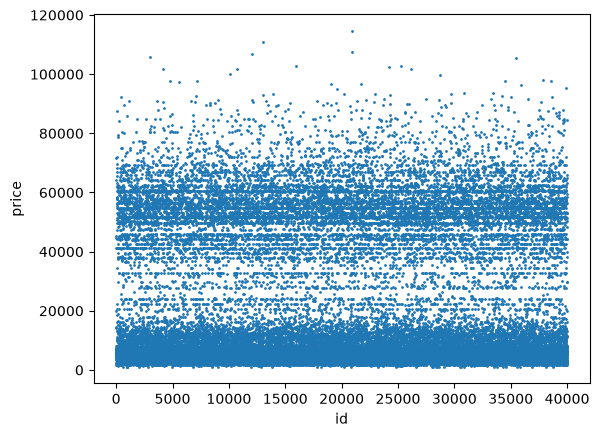

In [45]:
raw = pd.read_csv('train.csv')
print(raw[['id', 'price']].corr())
raw.plot.scatter(x='id', y='price', s=1)

In [46]:
rf = best_models['rf']
print('train R2:', r2_score(y_train, rf.predict(X_train)))
print('test  R2:', r2_score(y_test,  rf.predict(X_test)))

train R2: 0.9958903161172472
test  R2: 0.9745664634967904


## ROUGH

In [65]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

def make_pre():
    return ColumnTransformer([
        ('days', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                           ('sc', StandardScaler())]), ['days_left']),
        ('dur',  StandardScaler(), ['duration']),
        ('nom',  OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                 ['airline', 'source', 'destination', 'departure', 'arrival']),
        ('ord',  OrdinalEncoder(categories=[['zero', 'one', 'two_or_more'],
                                            ['Economy', 'Business']]), ['stops', 'class']),
        ('flt',  OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ['flight']),
    ])

exp_rf_params = dict(n_estimators=400, max_features=0.8, min_samples_leaf=1,
                     n_jobs=-1, random_state=42)

exp_results = {'baseline (round 1 rf)': 0.9746}

In [66]:
exp_a = TransformedTargetRegressor(
    regressor=Pipeline([('pre', exp_pre), ('reg', RandomForestRegressor(**exp_rf_params))]),
    func=np.log1p, inverse_func=np.expm1)
exp_a.fit(X_train, y_train)

exp_results['flight + log'] = r2_score(y_test, exp_a.predict(X_test))
print(exp_results['flight + log'])

0.980323671064472


In [73]:
exp_b = Pipeline([('pre', exp_pre), ('reg', RandomForestRegressor(**exp_rf_params))])
exp_b.fit(X_train, y_train)

exp_results['flight, no log'] = r2_score(y_test, exp_b.predict(X_test))
print(exp_results['flight, no log'])

0.9802962416970943


In [76]:
exp_class_models = {}
for c in ['Economy', 'Business']:
    tr = X_train['class'] == c
    m = Pipeline([('pre', make_pre()), ('reg', RandomForestRegressor(**exp_rf_params))])
    exp_class_models[c] = m.fit(X_train[tr], y_train[tr])

In [68]:
import gc, joblib

joblib.dump(best_models['rf'], 'rf_round1.joblib')     # optional backup of your first submission model

del best_models2, results2          # round 2 gave no gain
del exp_a                           # if exp_b (no log) was the 98% one; otherwise del exp_b
best_models = {k: v for k, v in best_models.items() if k != 'rf'}   # drop the big RF, saved above
gc.collect()

KeyError: 'rf'

In [74]:
test = pd.read_csv('test.csv')
ids = test['id']

exp_test = clean_test(test)
exp_test['flight'] = test['flight'].values
exp_X = exp_test[X_train.columns]

In [75]:
pred_b = exp_b.predict(exp_X)
pd.DataFrame({'id': ids, 'price': pred_b.round().astype(int)}) \
  .to_csv('submission_flight_nolog.csv', index=False)

In [77]:
pred_c = pd.Series(index=exp_X.index, dtype=float)
for c, m in exp_class_models.items():
    idx = exp_X['class'] == c
    pred_c[idx] = m.predict(exp_X[idx])

pd.DataFrame({'id': ids, 'price': pred_c.round().astype(int)}) \
  .to_csv('submission_byclass.csv', index=False)